# Method 3: Similar-player KNN
Find players whose *low-minute* profile looks like this one, and average what *they* became.

- KNN cannot take a minutes input, so training rows are **bucketed by minutes** (6 buckets, 125 minutes wide). Per bucket the model is fit on one prefix per training player-season (the one closest to the bucket centre) and used for the test rows in that bucket.
- Distance: Euclidean on the standardized per-90 vector of all volume stats in the group (standardized per bucket).
- Estimate: the mean **full-season** profile of the K = 30 nearest training players.
- K is fixed, not tuned (the sweep below shows how sensitive it is).

**Setup shared by every method.** One model per gender and position group, trained on every per-game prefix (the player's first k matches, up to 750 minutes) of the 900+ minute player-seasons, each with its full-season per-90 as the target. The same fitted model handles any number of minutes. Rates, ratios and percents are never estimated: they are rebuilt from the estimated per-90 volumes.

In [1]:
%matplotlib inline
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
# make the repo root importable no matter which folder the notebook is opened from
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "low_minute_player_analysis").is_dir())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from low_minute_player_analysis import notebook_helpers as nh
from low_minute_player_analysis import reconstruct_methods as rm
from low_minute_player_analysis import temporal_methods as tm
from low_minute_player_analysis import reconstruction_eval as ev

nh.apply_style()
r = nh.load_results("results")         # out-of-fold scores for every group, gender and method
V, R = nh.volume(r), nh.rates(r)       # volume stats / rates rebuilt from the estimated volumes
P = nh.load_paired("results")          # paired differences vs the final ridge, with bootstrap intervals
nh.describe(r)

79,101 scored rows | genders ['female', 'male'] | 7 groups | checkpoints [np.int64(250), np.int64(500), np.int64(750)] | methods ['raw', 'shrink', 'ridge', 'knn', 'ot_1d', 'ot_joint', 'ot_group', 'kalman', 'kalman_blend', 'ridge_kalman', 'gru']
volume stats scored: 113 | rebuilt rates scored: 74


## 1. Results across all 14 gender / position-group sets

**How to read the numbers.** `nrmse` is the RMSE of the estimate against the player's true full-season
per-90, divided by the standard deviation of that true value. 0 is perfect; 1 means no better than guessing
the group average. Every table shows the **median over stats** (and over groups/genders unless stated).
The three columns / x positions are **minutes bins** of the sample the estimate was made from: 250 = 0-375 minutes,
500 = 375-625, 750 = 625-750 (every per-game prefix of a held-out player is scored; each player-season counts once
per bin). Scores are out-of-fold: the 5 folds split players, so nobody is predicted by a model that saw them.

method,raw,knn
checkpoint,,
250,1.489,0.864
500,0.713,0.758
750,0.518,0.714


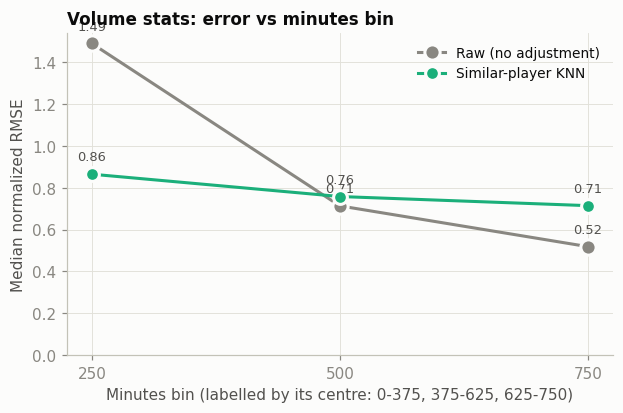

In [2]:
METHOD = "knn"
METHODS = ["raw", METHOD]
summary = nh.median_nrmse(V, METHODS)
display(summary.round(3))
nh.curve_plot(summary, METHODS, "Volume stats: error vs minutes bin")
plt.show()

Error reduction versus raw (median over stats) and by position group:

method,knn (% reduction)
minutes bin,
250,42.7
500,-3.2
750,-30.5


checkpoint,250,500,750
group,,,
Attacking Midfielders,37.7,-13.8,-48.1
Center Backs,45.9,2.3,-21.0
Center Forwards,40.4,-10.1,-43.7
Central Midfielders,40.2,-6.0,-32.5
GK,54.8,22.3,2.9
Outside Backs,43.0,-2.1,-26.5
Wingers,38.8,-15.8,-52.6


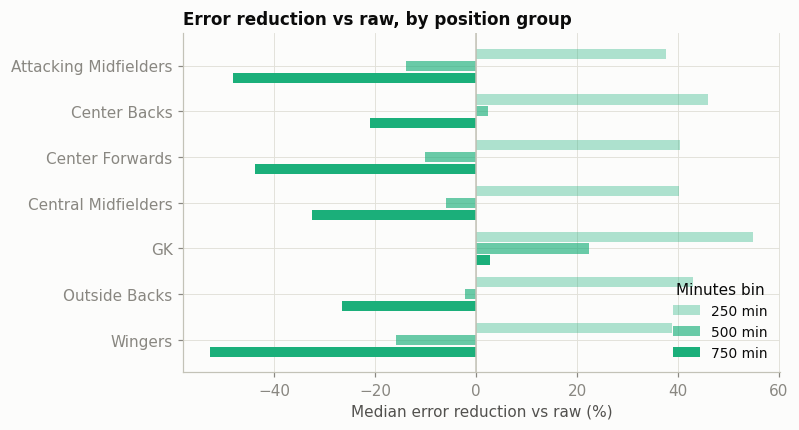

In [3]:
display(nh.improvement_table(V, [METHOD]).mul(100).round(1).rename_axis("minutes bin").add_suffix(" (% reduction)"))
by_group = nh.improvement_by_group(V, METHOD)
display(by_group.mul(100).round(1))
nh.group_bars(by_group, METHOD, "Error reduction vs raw, by position group")
plt.show()

Which stats improve most and least in the 500 bin?

In [4]:
best, worst = nh.per_stat(V, METHOD, 500)
display(pd.DataFrame({"most improved": best.mul(100).round(1)}))
display(pd.DataFrame({"least improved / worse": worst.mul(100).round(1)}))

,most improved
stat,
gk_clean_sheets,29.1
xa_minus_assists,27.7
goals_minus_xg,27.1
third_assists,25.2
goals_prevented,24.8
assists,24.4
direct_red_cards,24.3
red_cards,23.7


,least improved / worse
stat,
corners,-65.9
free_kicks,-53.4
offensive_duels,-40.3
field_aerial_duels,-37.5
accelerations,-35.7
field_aerial_duels_won,-31.4
aerial_duels,-31.2
failed_offensive_duels,-30.9


### Rates rebuilt from the estimated volumes
Percents, ratios and shares are **not** estimated directly. They are recomputed from the estimated per-90 volumes with the repo formulas (`rate_rebuild.py`). A rate is compared only where both the truth and the estimate exist; the share of rates the estimate could not produce is reported separately.

In [5]:
display(nh.median_nrmse(R, METHODS).round(3).rename_axis("minutes bin"))
display(nh.rate_table(R, METHODS, cp=500).round(3))
display(nh.missing_table(R, METHODS).round(4))

method,raw,knn
minutes bin,,
250,1.737,0.933
500,0.838,0.875
750,0.610,0.847


method,raw,knn
stat_type,,
rate_api_approx,0.844,0.848
rate_api_exact,1.031,0.964
rate_derived,0.754,0.807


,n_truth_ok,n_est_missing,n_compared,est_missing_share
method,,,,
raw,17532604,1039980,16492624,0.0593
knn,17532604,205591,17327013,0.0117


## 2. Worked example: male Wingers (live run)
This re-runs the method out-of-fold on one group so every step below is reproducible here (the full results above came from `reconstruction_eval.py`).

raw     median nrmse @250/500/750: [1.378, 0.627, 0.451]
knn     median nrmse @250/500/750: [0.865, 0.766, 0.726]


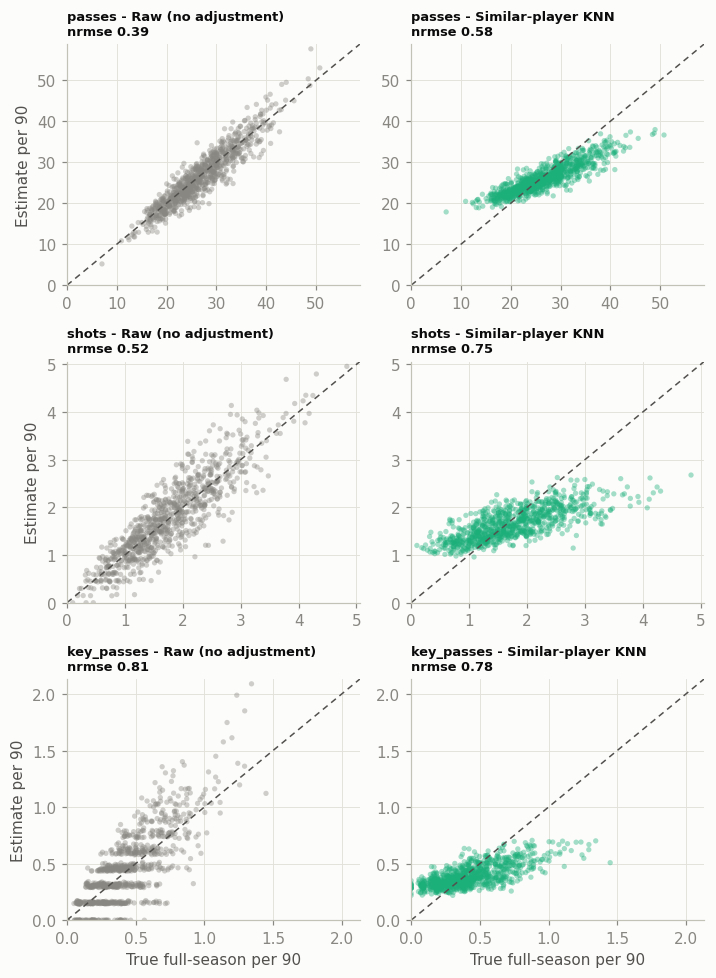

In [6]:
pool, stems, est = nh.demo_group("male", "Wingers", ["raw", METHOD])
for m in ["raw", METHOD]:
    print(f"{m:7s} median nrmse @250/500/750:",
          [round(float(nh.nrmse_per_stat(pool, est[m], b).median()), 3) for b in (250, 500, 750)])
fig = nh.scatter_grid(pool, est, ["passes", "shots", "key_passes"], 500, ["raw", METHOD])
plt.show()

### Diagnostic: how sensitive is the result to K?
Median normalized RMSE in the 500 bin for different K, same out-of-fold folds. The dashed line is the raw baseline.

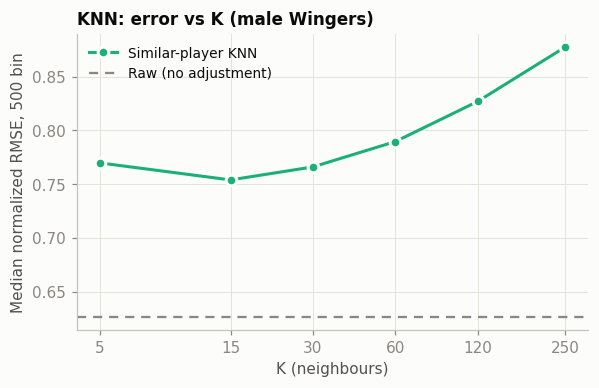

{5: np.float64(0.77), 15: np.float64(0.754), 30: np.float64(0.766), 60: np.float64(0.79), 120: np.float64(0.827), 250: np.float64(0.877)}


In [7]:
stems_, folds = ev.group_setup("male", "Wingers")
ks, scores = [5, 15, 30, 60, 120, 250], []
saved = rm.KNN_K
for kk in ks:
    rm.KNN_K = kk
    e = ev.oof_predictions(pool, folds, stems, ["knn"])["knn"]
    scores.append(float(nh.nrmse_per_stat(pool, e, 500).median()))
rm.KNN_K = saved
raw_score = float(nh.nrmse_per_stat(pool, est["raw"], 500).median())
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(ks, scores, marker="o", ms=7, lw=2, color=nh.COLORS["knn"], markeredgecolor=nh.SURFACE, markeredgewidth=2, label=nh.LABELS["knn"])
ax.axhline(raw_score, color=nh.COLORS["raw"], lw=1.5, ls=(0, (4, 3)), label=nh.LABELS["raw"])
ax.set_xscale("log"); ax.set_xticks(ks, [str(k) for k in ks]); ax.minorticks_off()
ax.set_xlabel("K (neighbours)"); ax.set_ylabel("Median normalized RMSE, 500 bin")
ax.set_title("KNN: error vs K (male Wingers)", loc="left"); ax.legend(); plt.show()
print(dict(zip(ks, np.round(scores, 3))))

### Strengths and limits
- Easy to explain, and it never predicts a profile that no real player has.
- Neighbours are found in about 100 noisy dimensions, so the "similar" players are partly similar by chance. This is why it falls behind raw as minutes grow. Larger K or fewer features would likely help; it has not been tuned.